In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

In [4]:
df = pd.read_csv("../data/raw/credit.csv")
df.head()

,LIMIT_BAL,SEX,EDUCATION,MARRIAGE,AGE,PAY_1,PAY_2,PAY_3,PAY_4,PAY_5,...,BILL_AMT4,BILL_AMT5,BILL_AMT6,PAY_AMT1,PAY_AMT2,PAY_AMT3,PAY_AMT4,PAY_AMT5,PAY_AMT6,default
0,20000,2,2,1,24,2,2,-1,-1,-2,...,0.0,0.0,0.0,0.0,689.0,0.0,0.0,0.0,0.0,1
1,90000,2,2,2,34,0,0,0,0,0,...,14331.0,14948.0,15549.0,1518.0,1500.0,1000.0,1000.0,1000.0,5000.0,0
2,50000,2,2,1,37,0,0,0,0,0,...,28314.0,28959.0,29547.0,2000.0,2019.0,1200.0,1100.0,1069.0,1000.0,0
3,50000,1,2,1,57,-1,0,-1,0,0,...,20940.0,19146.0,19131.0,2000.0,36681.0,10000.0,9000.0,689.0,679.0,0
4,50000,1,1,2,37,0,0,0,0,0,...,19394.0,19619.0,20024.0,2500.0,1815.0,657.0,1000.0,1000.0,800.0,0


In [5]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 24000 entries, 0 to 23999
Data columns (total 24 columns):
 #   Column     Non-Null Count  Dtype  
---  ------     --------------  -----  
 0   LIMIT_BAL  24000 non-null  int64  
 1   SEX        24000 non-null  int64  
 2   EDUCATION  24000 non-null  int64  
 3   MARRIAGE   24000 non-null  int64  
 4   AGE        24000 non-null  int64  
 5   PAY_1      24000 non-null  int64  
 6   PAY_2      24000 non-null  int64  
 7   PAY_3      24000 non-null  int64  
 8   PAY_4      24000 non-null  int64  
 9   PAY_5      24000 non-null  int64  
 10  PAY_6      24000 non-null  int64  
 11  BILL_AMT1  24000 non-null  float64
 12  BILL_AMT2  24000 non-null  float64
 13  BILL_AMT3  24000 non-null  float64
 14  BILL_AMT4  24000 non-null  float64
 15  BILL_AMT5  24000 non-null  float64
 16  BILL_AMT6  24000 non-null  float64
 17  PAY_AMT1   24000 non-null  float64
 18  PAY_AMT2   24000 non-null  float64
 19  PAY_AMT3   24000 non-null  float64
 20  PAY_AM

In [11]:
df.duplicated().sum()

np.int64(24)

In [6]:
df.describe().T

,count,mean,std,min,25%,50%,75%,max
LIMIT_BAL,24000.0,167876.403333,129907.454723,10000.0,50000.00,140000.0,240000.00,1000000.0
SEX,24000.0,1.600917,0.489720,1.0,1.00,2.0,2.00,2.0
EDUCATION,24000.0,1.850958,0.787361,0.0,1.00,2.0,2.00,6.0
MARRIAGE,24000.0,1.553000,0.521331,0.0,1.00,2.0,2.00,3.0
AGE,24000.0,35.446708,9.180845,21.0,28.00,34.0,41.00,79.0
PAY_1,24000.0,-0.023875,1.123806,-2.0,-1.00,0.0,0.00,8.0
PAY_2,24000.0,-0.140500,1.194216,-2.0,-1.00,0.0,0.00,8.0
PAY_3,24000.0,-0.170000,1.198712,-2.0,-1.00,0.0,0.00,8.0
PAY_4,24000.0,-0.221500,1.171784,-2.0,-1.00,0.0,0.00,8.0
PAY_5,24000.0,-0.266833,1.133220,-2.0,-1.00,0.0,0.00,8.0


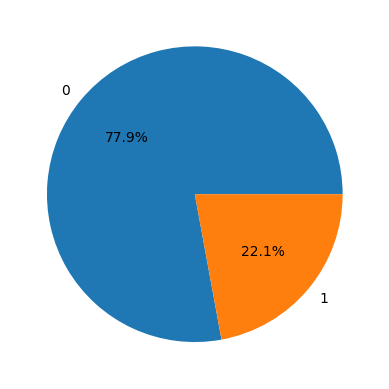

In [7]:
# Target Column: default
default_counts = df["default"].value_counts(normalize=True)*100
plt.pie(labels=default_counts.index,x=default_counts.values,autopct='%1.1f%%')
plt.show()

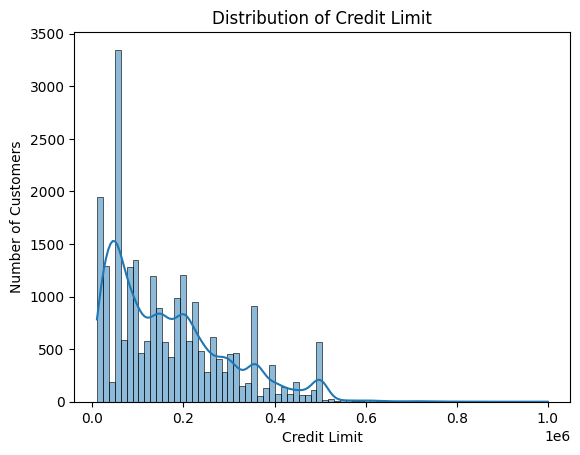

In [8]:
# LIMIT_BAL
sns.histplot(data=df,x="LIMIT_BAL",kde=True)

plt.title("Distribution of Credit Limit")
plt.xlabel("Credit Limit")
plt.ylabel("Number of Customers")

plt.show()

In [9]:
# To see if default interact with LIMIT_BAL
df.groupby("default")["LIMIT_BAL"].agg(
    ["mean", "median", "std", "min", "max"])

,mean,median,std,min,max
default,,,,,
0,178306.729432,150000.0,131869.795757,10000,1000000
1,131128.473426,90000.0,115477.307582,10000,740000


In [12]:
# Now let's default rate at different LIMIT_BAL by deviding in quartiles
df["LIMIT_BAL_BIN"] = pd.qcut(df["LIMIT_BAL"],q=4)

limit_default = (
    df.groupby("LIMIT_BAL_BIN", observed=True)["default"]
      .agg(["mean", "count"])
)

print(limit_default)

# default rate is higher at lower quartiles

                           mean  count
LIMIT_BAL_BIN                         
(9999.999, 50000.0]    0.314636   6115
(50000.0, 140000.0]    0.245490   6098
(140000.0, 240000.0]   0.177873   6083
(240000.0, 1000000.0]  0.140778   5704


SEX
2    60.091667
1    39.908333
Name: proportion, dtype: float64


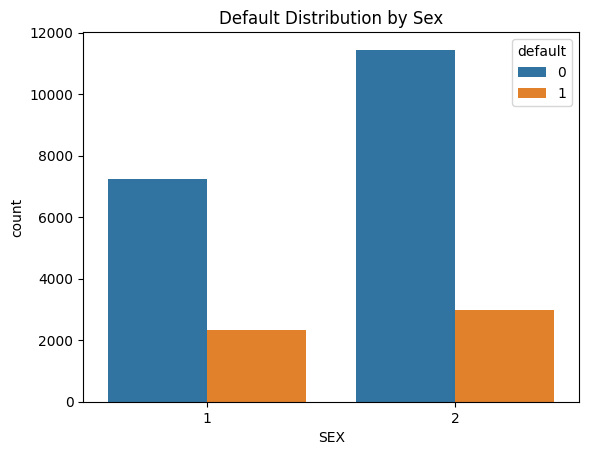

In [13]:
# SEX
gender_counts = df["SEX"].value_counts(normalize=True)*100
print(gender_counts)

#Let's see whether sex affects the default
sns.countplot(
    data=df,
    x="SEX",
    hue="default"
)
plt.title("Default Distribution by Sex")
plt.show()


In [14]:
# It doesn't to make a much of a difference
sex_default = (
    df.groupby("SEX")["default"]
      .mean()
      .reset_index()
)

print(sex_default)

   SEX   default
0    1  0.242953
1    2  0.206559


In [15]:
#EDUCATION
education_counts = df["EDUCATION"].value_counts(normalize=True)*100
print(education_counts)

EDUCATION
2    46.720833
1    35.358333
3    16.433333
5     0.904167
4     0.375000
6     0.162500
0     0.045833
Name: proportion, dtype: float64


   EDUCATION   default
0          0  0.000000
1          1  0.192788
2          2  0.237492
3          3  0.249493
4          4  0.044444
5          5  0.055300
6          6  0.179487


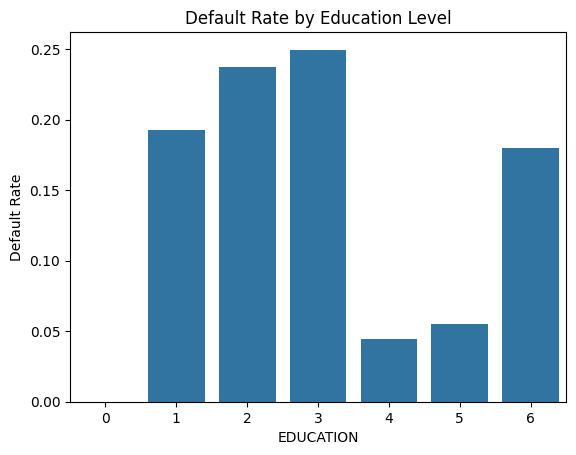

In [16]:
#Now let's see how education affects default

education_default = (
    df.groupby("EDUCATION")["default"]
      .mean()
      .reset_index()
)

print(education_default)

sns.barplot(
    data=education_default,
    x="EDUCATION",
    y="default"
)

plt.title("Default Rate by Education Level")
plt.ylabel("Default Rate")

plt.show()

In [17]:
# It doesn't correlate properly after reviewing the proportions of each category
education_summary = (
    df.groupby("EDUCATION")["default"]
      .agg(["mean", "count"])
)

print(education_summary)

               mean  count
EDUCATION                 
0          0.000000     11
1          0.192788   8486
2          0.237492  11213
3          0.249493   3944
4          0.044444     90
5          0.055300    217
6          0.179487     39


In [18]:
#MARRIAGE
marriage_counts = df["MARRIAGE"].value_counts(normalize=True)*100
print(marriage_counts)
# sns.barplot(x=marriage_counts.index,y=marriage_counts.values)
# plt.show()

MARRIAGE
2    53.366667
1    45.404167
3     1.054167
0     0.175000
Name: proportion, dtype: float64


   MARRIAGE   default
0         0  0.095238
1         1  0.235111
2         2  0.208542
3         3  0.272727


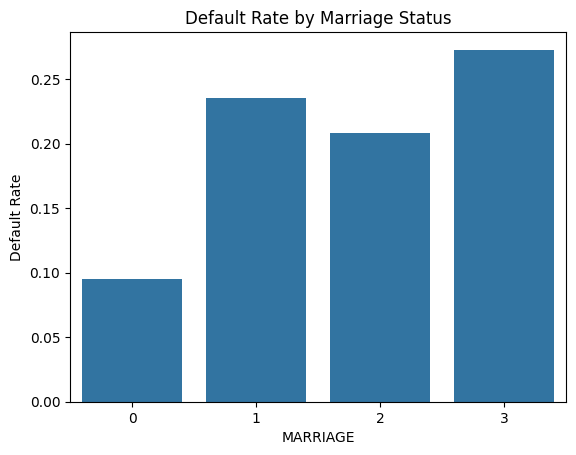

In [19]:
#Does Marriage Status Matter??
marriage_default = (
    df.groupby("MARRIAGE")["default"]
      .mean()
      .reset_index()
)

print(marriage_default)

sns.barplot(
    data=marriage_default,
    x="MARRIAGE",
    y="default"
)

plt.title("Default Rate by Marriage Status")
plt.ylabel("Default Rate")

plt.show()

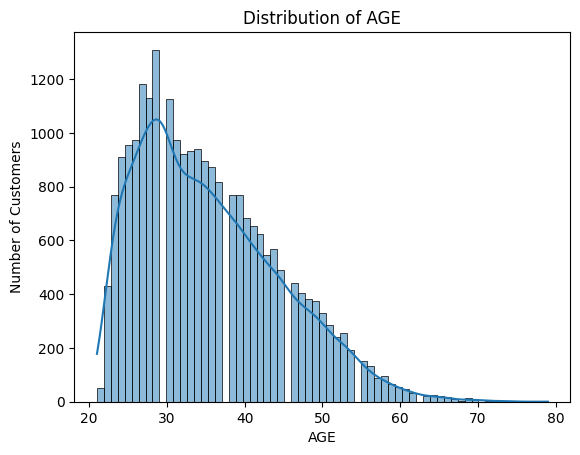

In [20]:
#AGE
sns.histplot(data=df,x="AGE",kde=True)

plt.title("Distribution of AGE")
plt.xlabel("AGE")
plt.ylabel("Number of Customers")

plt.show()

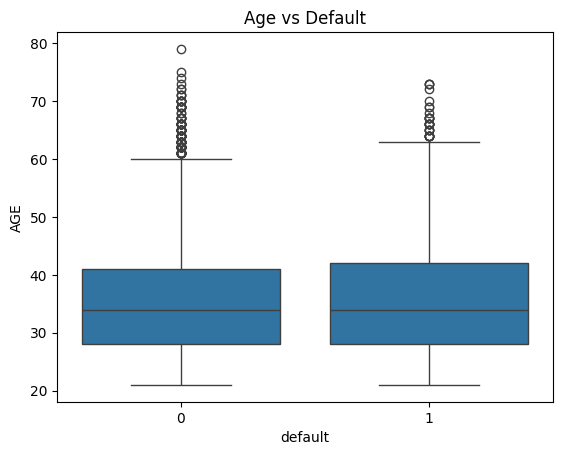

In [21]:
sns.boxplot(
    data=df,
    x="default",
    y="AGE"
)

plt.title("Age vs Default")
plt.show()

               mean  count
AGE_GROUP                 
(20, 25]   0.260995   3115
(25, 30]   0.205558   5721
(30, 35]   0.196099   4666
(35, 40]   0.212276   3910
(40, 45]   0.221875   2880
(45, 50]   0.249482   1932
(50, 60]   0.252396   1565
(60, 80]   0.265403    211


<Axes: xlabel='AGE_GROUP', ylabel='mean'>

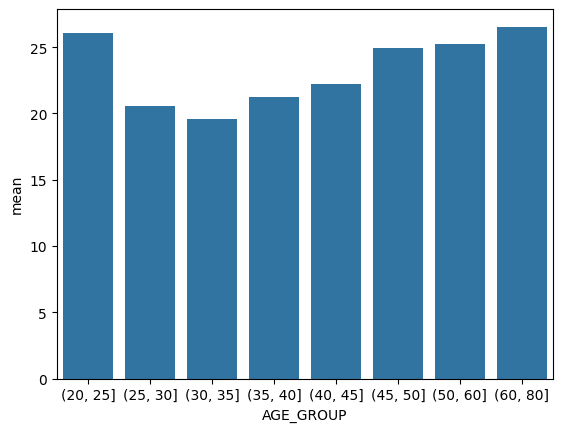

In [23]:
#After observing the boxplots, I see difference but a bit less
#So now lets bin up the age to see if different age group contribut differently

age_bins = [20, 25, 30, 35, 40, 45, 50, 60, 80]

df["AGE_GROUP"] = pd.cut(
    df["AGE"],
    bins=age_bins
)

age_default = (
    df.groupby("AGE_GROUP", observed=True)["default"]
      .agg(["mean", "count"])
)

print(age_default)

sns.barplot(
    x=age_default.index.astype(str),
    y=age_default["mean"] * 100
)

# Visualizing the bars, a little bit of u shape is seen
# this indicates the elderly and the young people are more likely to default

In [24]:
#PAY - status (delays possibly)

pay_cols = [f"PAY_{i}" for i in range(1, 7)]

for col in pay_cols:
    print(col, sorted(df[col].unique()))

PAY_1 [np.int64(-2), np.int64(-1), np.int64(0), np.int64(1), np.int64(2), np.int64(3), np.int64(4), np.int64(5), np.int64(6), np.int64(7), np.int64(8)]
PAY_2 [np.int64(-2), np.int64(-1), np.int64(0), np.int64(1), np.int64(2), np.int64(3), np.int64(4), np.int64(5), np.int64(6), np.int64(7), np.int64(8)]
PAY_3 [np.int64(-2), np.int64(-1), np.int64(0), np.int64(1), np.int64(2), np.int64(3), np.int64(4), np.int64(5), np.int64(6), np.int64(7), np.int64(8)]
PAY_4 [np.int64(-2), np.int64(-1), np.int64(0), np.int64(1), np.int64(2), np.int64(3), np.int64(4), np.int64(5), np.int64(6), np.int64(7), np.int64(8)]
PAY_5 [np.int64(-2), np.int64(-1), np.int64(0), np.int64(2), np.int64(3), np.int64(4), np.int64(5), np.int64(6), np.int64(7), np.int64(8)]
PAY_6 [np.int64(-2), np.int64(-1), np.int64(0), np.int64(2), np.int64(3), np.int64(4), np.int64(5), np.int64(6), np.int64(7), np.int64(8)]


In [25]:
# Let's see if different categories of PAY yeild different results
pay1_default = (
    df.groupby("PAY_1")["default"]
      .agg(["mean", "count"])
)

print(pay1_default)

# It does. More delays of payment yeilds more default rate

           mean  count
PAY_1                 
-2     0.130041   2207
-1     0.170621   4636
 0     0.128177  11765
 1     0.338493   2907
 2     0.696286   2127
 3     0.757085    247
 4     0.636364     55
 5     0.545455     22
 6     0.600000     10
 7     0.714286      7
 8     0.588235     17


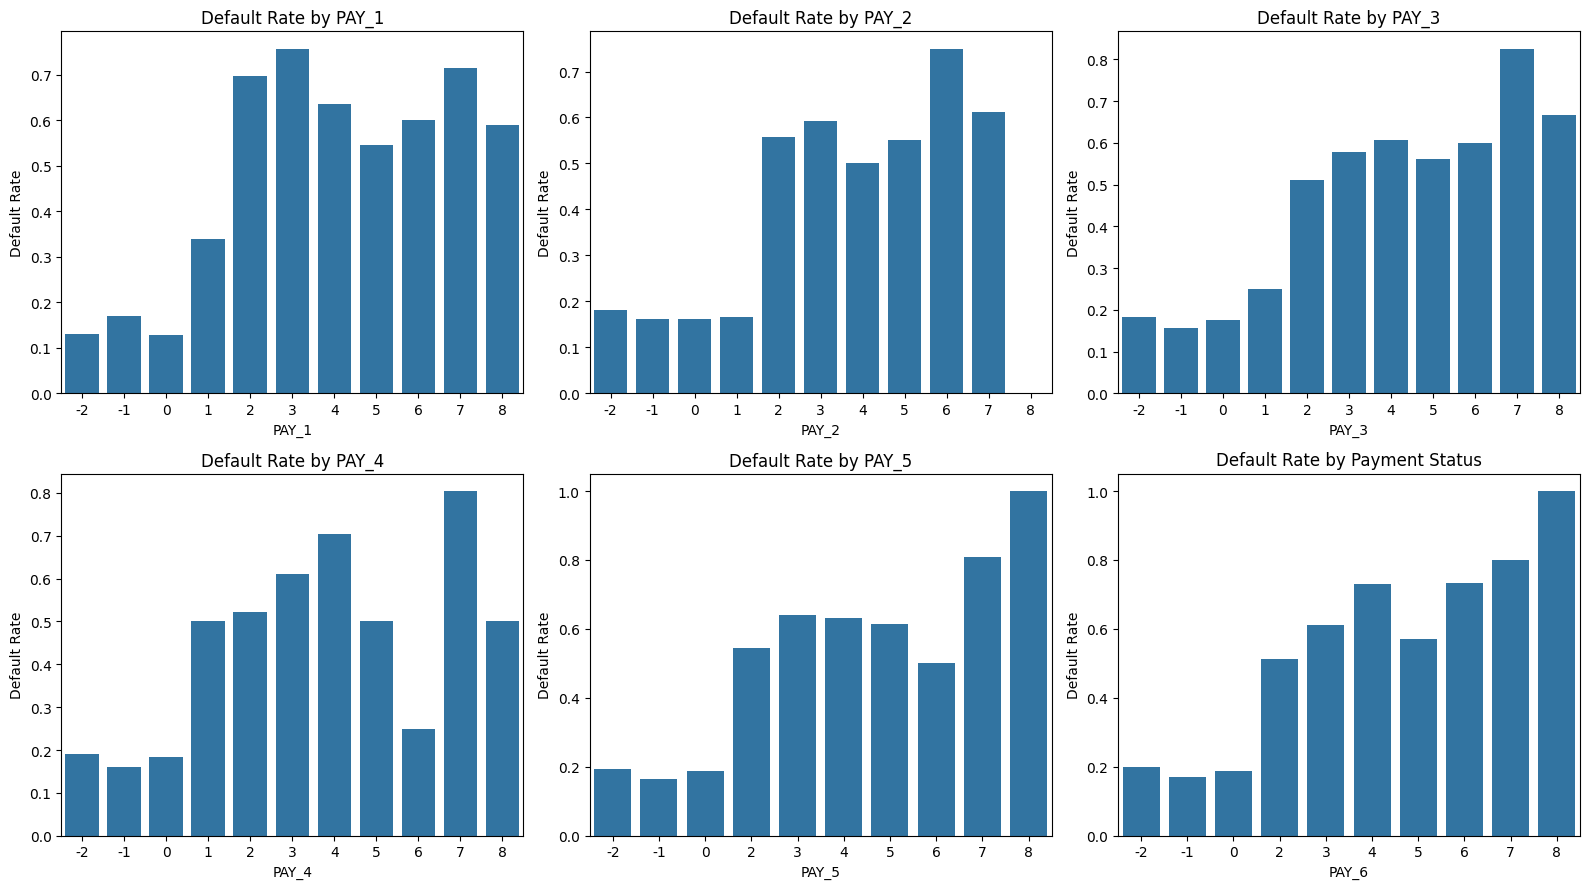

In [26]:
#Now let's see if this holds the same for the rest PAYs
fig, axes = plt.subplots(2, 3, figsize=(16, 9))

for ax, col in zip(axes.flatten(), pay_cols):

    temp = (
        df.groupby(col)["default"]
          .mean()
          .reset_index()
    )

    sns.barplot(
        data=temp,
        x=col,
        y="default",
        errorbar=None,
        ax=ax
    )

    ax.set_title(f"Default Rate by {col}")
    ax.set_ylabel("Default Rate")
plt.title("Default Rate by Payment Status")
plt.tight_layout()
plt.show()


# With a little bit of fluctuations different pay increasing does efeect the default increase

In [27]:
# Now lets see how the late payment affects with default
df["late_payment_count"] = (
    df[pay_cols] >= 1
).sum(axis=1)

df["late_payment_count"].value_counts()

late_payment_count
0    15960
1     3564
2     1518
6     1076
3      906
4      744
5      232
Name: count, dtype: int64

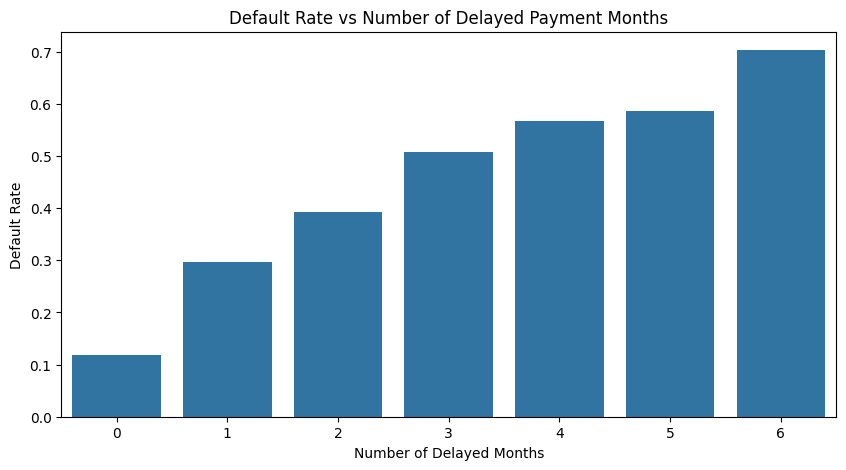

In [28]:
plt.figure(figsize=(10, 5))

sns.barplot(
    data=df,
    x="late_payment_count",
    y="default",
    errorbar=None
)

plt.title("Default Rate vs Number of Delayed Payment Months")
plt.xlabel("Number of Delayed Months")
plt.ylabel("Default Rate")

plt.show()

#As the delay increases the default ratio is also increased

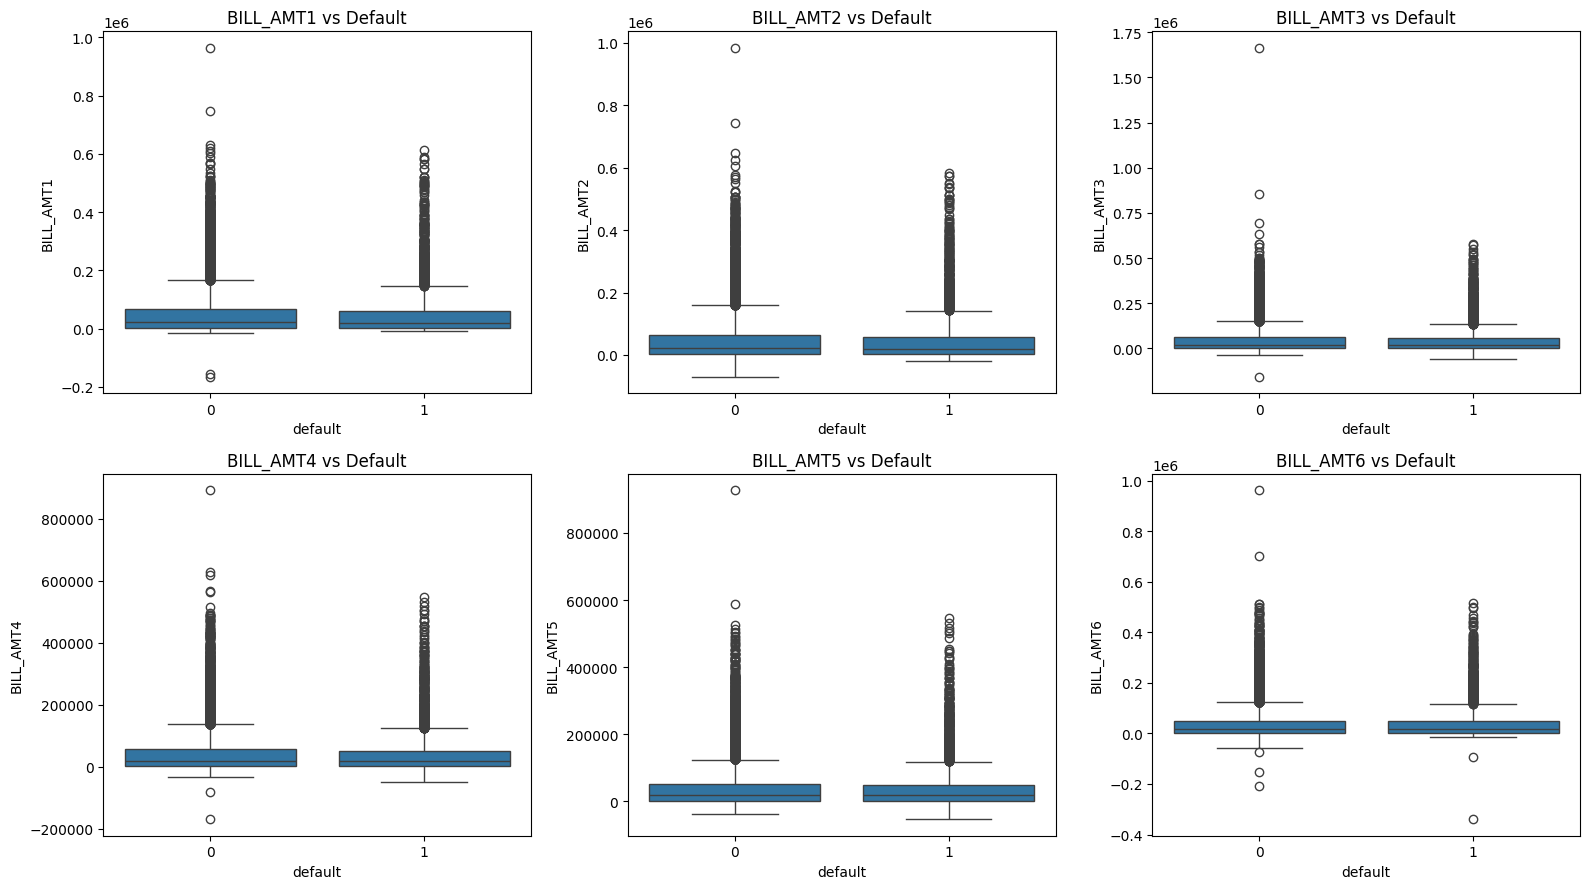

In [29]:
# BILL_AMT

bill_cols = [f"BILL_AMT{i}" for i in range(1, 7)]

fig, axes = plt.subplots(2, 3, figsize=(16, 9))

for ax, col in zip(axes.flatten(), bill_cols):

    sns.boxplot(
        data=df,
        x="default",
        y=col,
        ax=ax
    )

    ax.set_title(f"{col} vs Default")

plt.tight_layout()
plt.show()

# The boxes for BILL_AMT are at same level
#So I don't think they are important for defaults

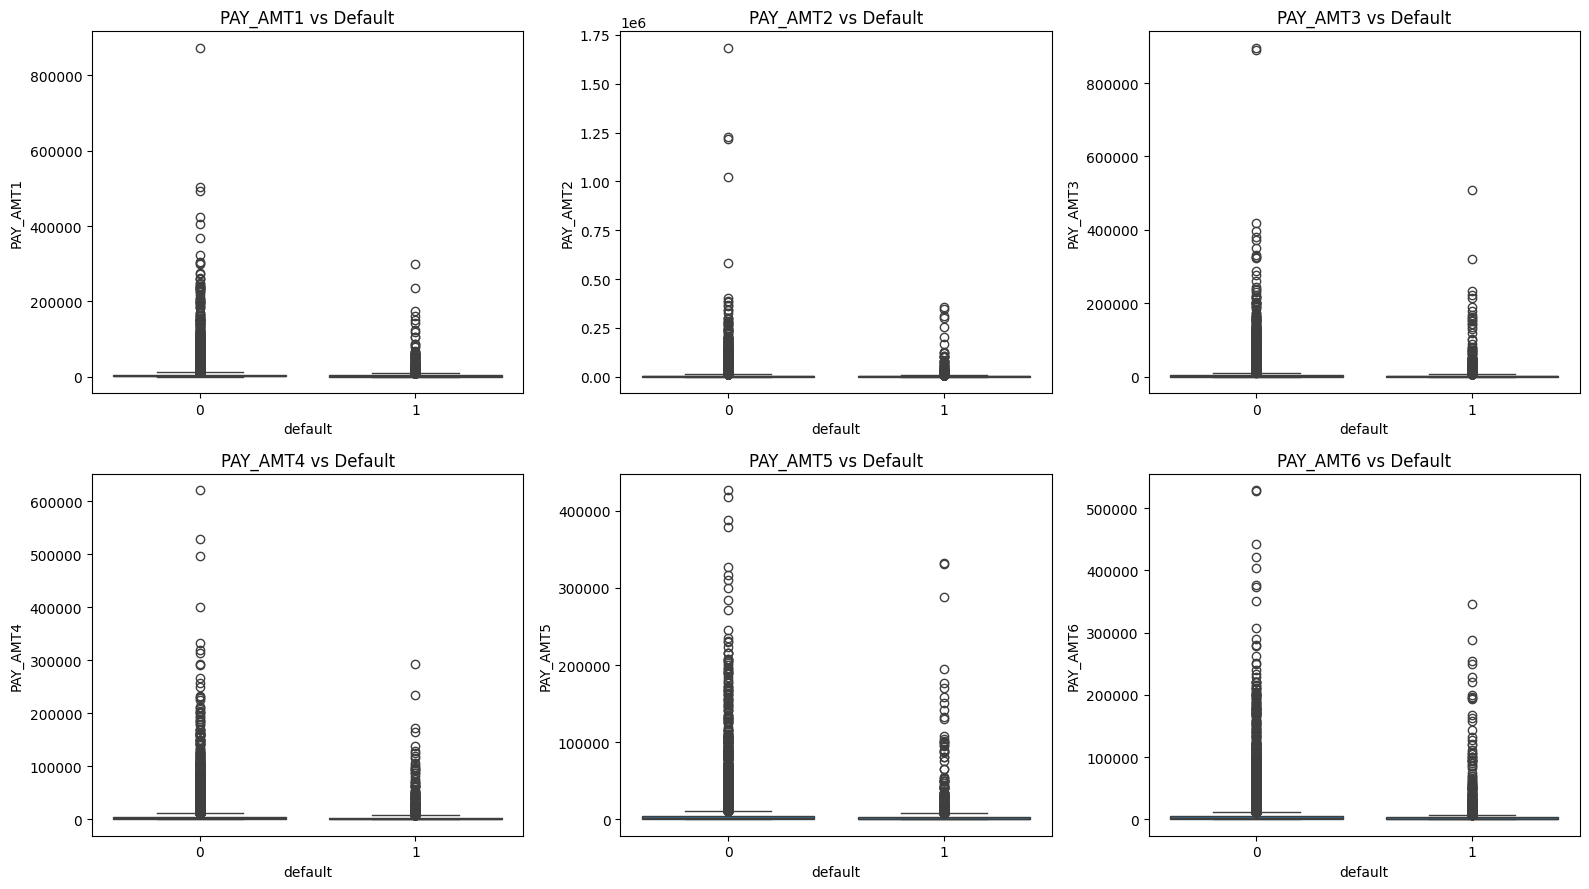

In [30]:
# PAY_AMT

pay_amt_cols = [f"PAY_AMT{i}" for i in range(1, 7)]

fig, axes = plt.subplots(2, 3, figsize=(16, 9))

for ax, col in zip(axes.flatten(), pay_amt_cols):

    sns.boxplot(
        data=df,
        x="default",
        y=col,
        ax=ax
    )

    ax.set_title(f"{col} vs Default")

plt.tight_layout()
plt.show()

#Same goes here as the BILL_AMT

In [31]:
#As both PAY_AMT and BILL_AMT doen't correlate properly
#So let's create payment ratio. We can later drop those columns
#and take only pay_ratio

for i in range(1, 7):

    df[f"PAY_RATIO_{i}"] = (
        df[f"PAY_AMT{i}"] /
        (df[f"BILL_AMT{i}"].abs()+1)
    )
ratio_cols = [f"PAY_RATIO_{i}" for i in range(1, 7)]

df.groupby("default")[ratio_cols].median()

,PAY_RATIO_1,PAY_RATIO_2,PAY_RATIO_3,PAY_RATIO_4,PAY_RATIO_5,PAY_RATIO_6
default,,,,,,
0,0.062252,0.060025,0.048127,0.041291,0.044051,0.043704
1,0.047621,0.046516,0.037974,0.036968,0.038127,0.037697


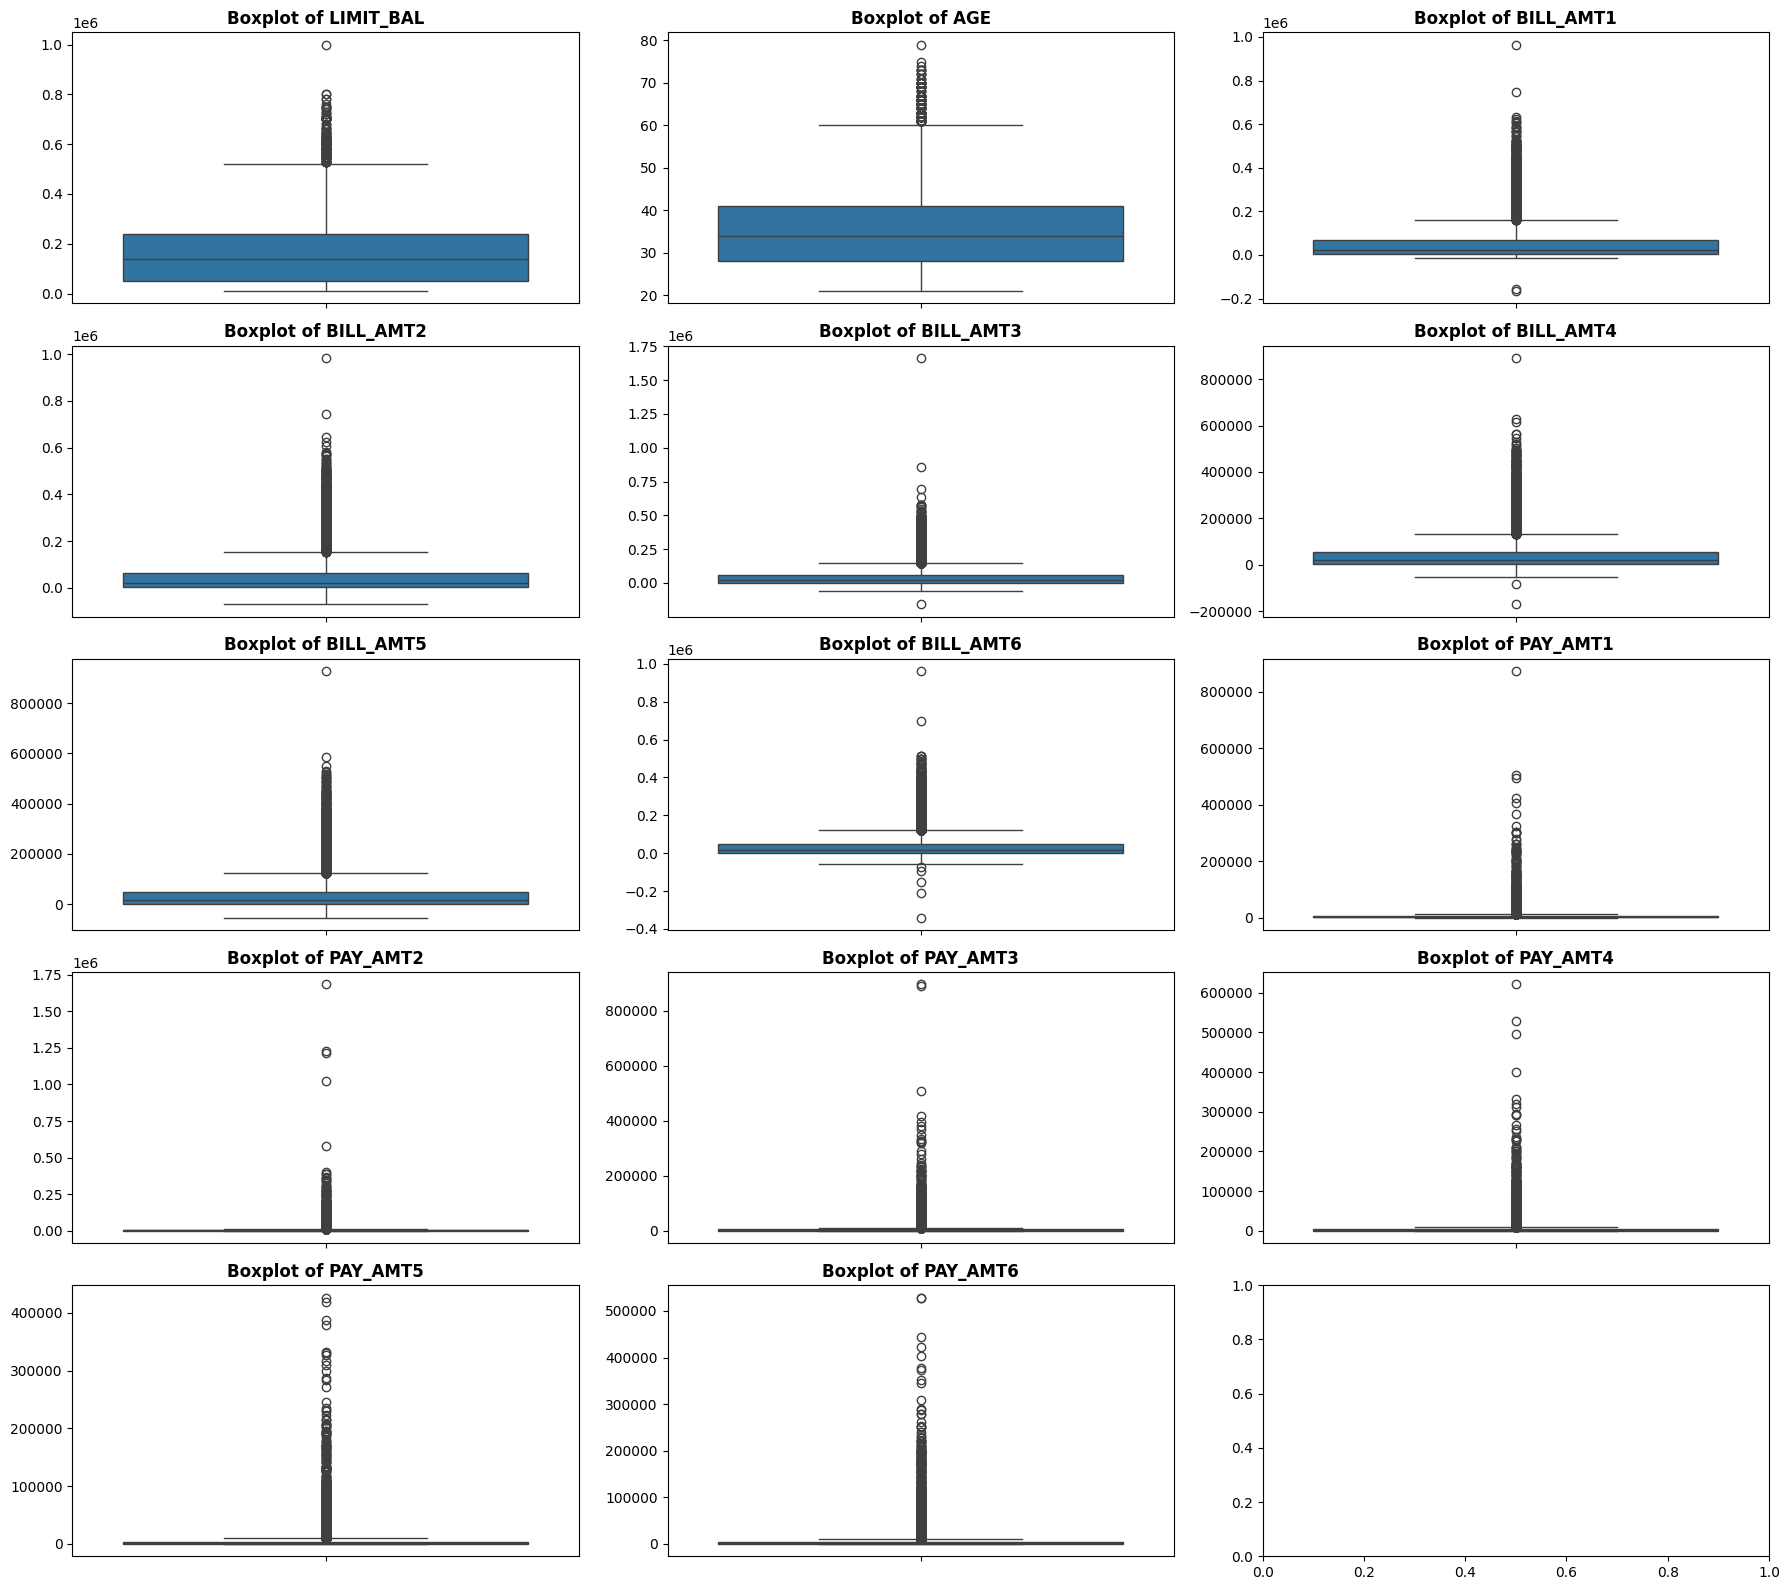

In [34]:
num_columns = ['LIMIT_BAL','AGE','BILL_AMT1', 'BILL_AMT2','BILL_AMT3', 'BILL_AMT4',
               'BILL_AMT5', 'BILL_AMT6', 'PAY_AMT1','PAY_AMT2',
               'PAY_AMT3', 'PAY_AMT4', 'PAY_AMT5', 'PAY_AMT6']

fig, axes = plt.subplots(nrows=5, ncols=3, figsize=(18, 16))

axes = axes.flatten()

for i, col in enumerate(num_columns):
    sns.boxplot(
        data=df,
        y=col,
        ax=axes[i]
    )
    axes[i].set_title(f"Boxplot of {col}", fontsize=12, fontweight="bold")
    axes[i].set_ylabel("")

plt.tight_layout()
plt.show()

In [32]:
# Now let's see correlations of features with target
correlation = (
    df.corr(numeric_only=True)["default"]
      .drop("default")
      .sort_values()
)

print(correlation)

LIMIT_BAL            -0.150709
PAY_AMT1             -0.070321
PAY_AMT4             -0.058028
PAY_AMT5             -0.056323
PAY_AMT2             -0.055658
PAY_AMT3             -0.053787
PAY_AMT6             -0.050924
SEX                  -0.042947
MARRIAGE             -0.024888
BILL_AMT1            -0.017452
PAY_RATIO_2          -0.012703
PAY_RATIO_6          -0.012531
BILL_AMT2            -0.012030
BILL_AMT3            -0.011895
PAY_RATIO_3          -0.009962
PAY_RATIO_4          -0.008075
BILL_AMT4            -0.007834
PAY_RATIO_5          -0.005589
PAY_RATIO_1          -0.004904
BILL_AMT5            -0.003082
BILL_AMT6            -0.002574
AGE                   0.013450
EDUCATION             0.026885
PAY_6                 0.189304
PAY_5                 0.206612
PAY_4                 0.216989
PAY_3                 0.234374
PAY_2                 0.259680
PAY_1                 0.323410
late_payment_count    0.397121
Name: default, dtype: float64


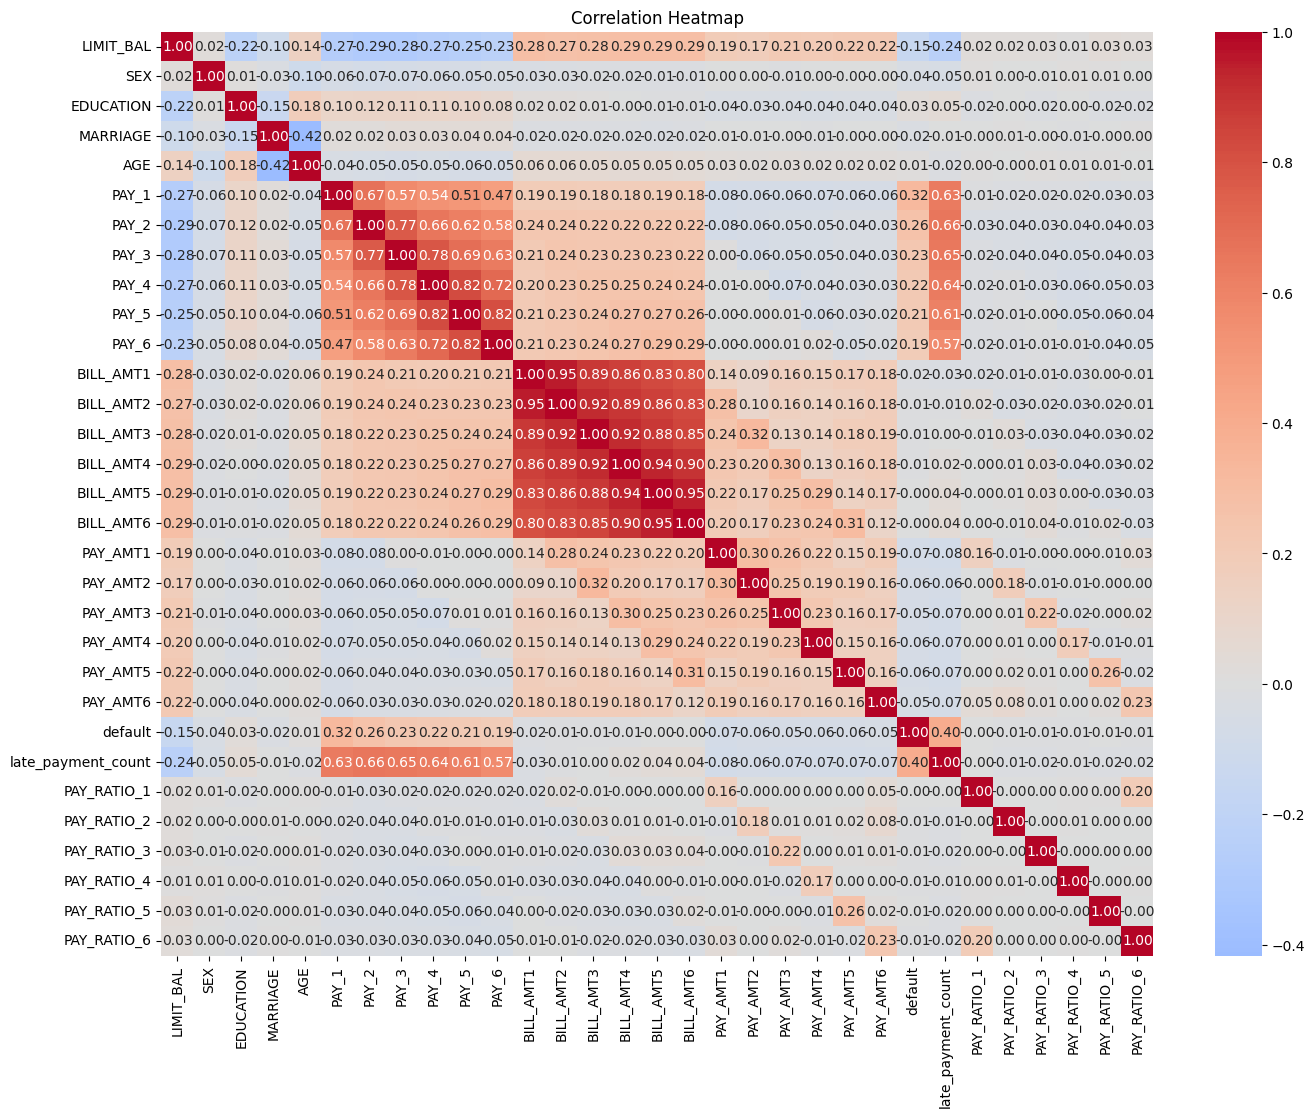

In [33]:
#Correlation Heatmap

plt.figure(figsize=(16, 12))
corr = df.corr(numeric_only=True)
sns.heatmap(
    corr,
    cmap="coolwarm",
    center=0,
    annot=True,
    fmt=".2f"
)

plt.title("Correlation Heatmap")

plt.show()